In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
import pandas as pd

# Correct way to load the dataset
df = pd.read_csv(r'/Users/adityavardhan/Downloads/day.csv')

# Display basic information about the dataset
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    object 
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.4+ KB


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,1,1,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,2,1,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,3,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,4,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,5,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [13]:
    # Drop the 'instant' column as it is just an index
df.drop(columns=['instant'], inplace=True)

# Convert 'dteday' to datetime format
df['dteday'] = pd.to_datetime(df['dteday'], format="%d-%m-%Y")

# Convert categorical variables to meaningful labels
df['season'] = df['season'].map({1: 'spring', 2: 'summer', 3: 'fall', 4: 'winter'})
df['weathersit'] = df['weathersit'].map({
    1: 'Clear', 
    2: 'Mist_Cloudy', 
    3: 'Light_Snow_Rain', 
    4: 'Heavy_Rain_Snow'
})

# Convert categorical variables to dtype 'category'
categorical_cols = ['season', 'weathersit', 'yr', 'mnth', 'weekday', 'holiday', 'workingday']
df[categorical_cols] = df[categorical_cols].astype('category')

# Display updated dataset info
df.info(), df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      730 non-null    datetime64[ns]
 1   season      730 non-null    category      
 2   yr          730 non-null    category      
 3   mnth        730 non-null    category      
 4   holiday     730 non-null    category      
 5   weekday     730 non-null    category      
 6   workingday  730 non-null    category      
 7   weathersit  730 non-null    category      
 8   temp        730 non-null    float64       
 9   atemp       730 non-null    float64       
 10  hum         730 non-null    float64       
 11  windspeed   730 non-null    float64       
 12  casual      730 non-null    int64         
 13  registered  730 non-null    int64         
 14  cnt         730 non-null    int64         
dtypes: category(7), datetime64[ns](1), float64(4), int64(3)
memory usage: 52.2

(None,
       dteday  season yr mnth holiday weekday workingday   weathersit  \
 0 2018-01-01  spring  0    1       0       1          1  Mist_Cloudy   
 1 2018-01-02  spring  0    1       0       2          1  Mist_Cloudy   
 2 2018-01-03  spring  0    1       0       3          1        Clear   
 3 2018-01-04  spring  0    1       0       4          1        Clear   
 4 2018-01-05  spring  0    1       0       5          1        Clear   
 
         temp     atemp      hum  windspeed  casual  registered   cnt  
 0  14.110847  18.18125  80.5833  10.749882     331         654   985  
 1  14.902598  17.68695  69.6087  16.652113     131         670   801  
 2   8.050924   9.47025  43.7273  16.636703     120        1229  1349  
 3   8.200000  10.60610  59.0435  10.739832     108        1454  1562  
 4   9.305237  11.46350  43.6957  12.522300      82        1518  1600  )

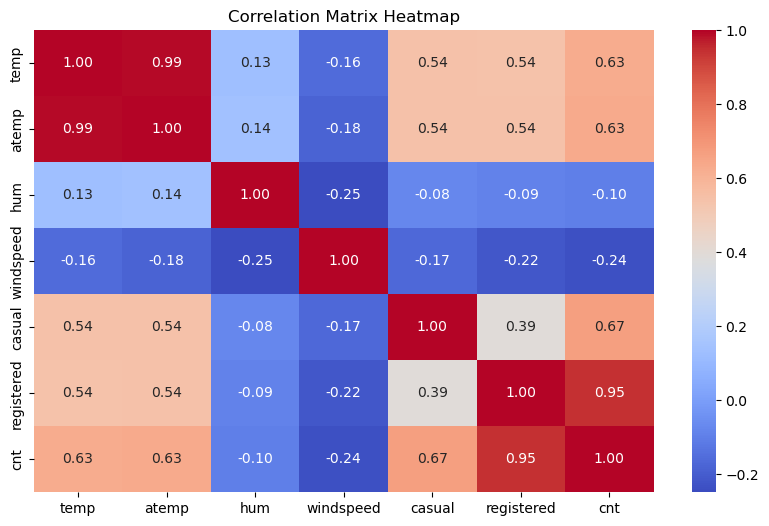

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your DataFrame (if not already loaded)
# df = pd.read_excel("Grade_woe_data.xlsx") 

# Select only numeric columns
numeric_df = df.select_dtypes(include=['number'])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()


In [25]:
print(df.columns)

Index(['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')


In [27]:
df_cleaned = df.drop(columns=["instant", "casual", "registered"], errors="ignore")


In [35]:
print(df_cleaned.head())


      dteday       temp     atemp      hum  windspeed   cnt  season_spring  \
0 2018-01-01  14.110847  18.18125  80.5833  10.749882   985           True   
1 2018-01-02  14.902598  17.68695  69.6087  16.652113   801           True   
2 2018-01-03   8.050924   9.47025  43.7273  16.636703  1349           True   
3 2018-01-04   8.200000  10.60610  59.0435  10.739832  1562           True   
4 2018-01-05   9.305237  11.46350  43.6957  12.522300  1600           True   

   season_summer  season_winter   yr_1  ...  holiday_1  weekday_1  weekday_2  \
0          False          False  False  ...      False       True      False   
1          False          False  False  ...      False      False       True   
2          False          False  False  ...      False      False      False   
3          False          False  False  ...      False      False      False   
4          False          False  False  ...      False      False      False   

   weekday_3  weekday_4  weekday_5  weekday_6  wor

      dteday  season yr mnth holiday weekday workingday   weathersit  \
0 2018-01-01  spring  0    1       0       1          1  Mist_Cloudy   
1 2018-01-02  spring  0    1       0       2          1  Mist_Cloudy   
2 2018-01-03  spring  0    1       0       3          1        Clear   
3 2018-01-04  spring  0    1       0       4          1        Clear   
4 2018-01-05  spring  0    1       0       5          1        Clear   

        temp     atemp      hum  windspeed   cnt  
0  14.110847  18.18125  80.5833  10.749882   985  
1  14.902598  17.68695  69.6087  16.652113   801  
2   8.050924   9.47025  43.7273  16.636703  1349  
3   8.200000  10.60610  59.0435  10.739832  1562  
4   9.305237  11.46350  43.6957  12.522300  1600  
Non-numeric columns: Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit'],
      dtype='object')


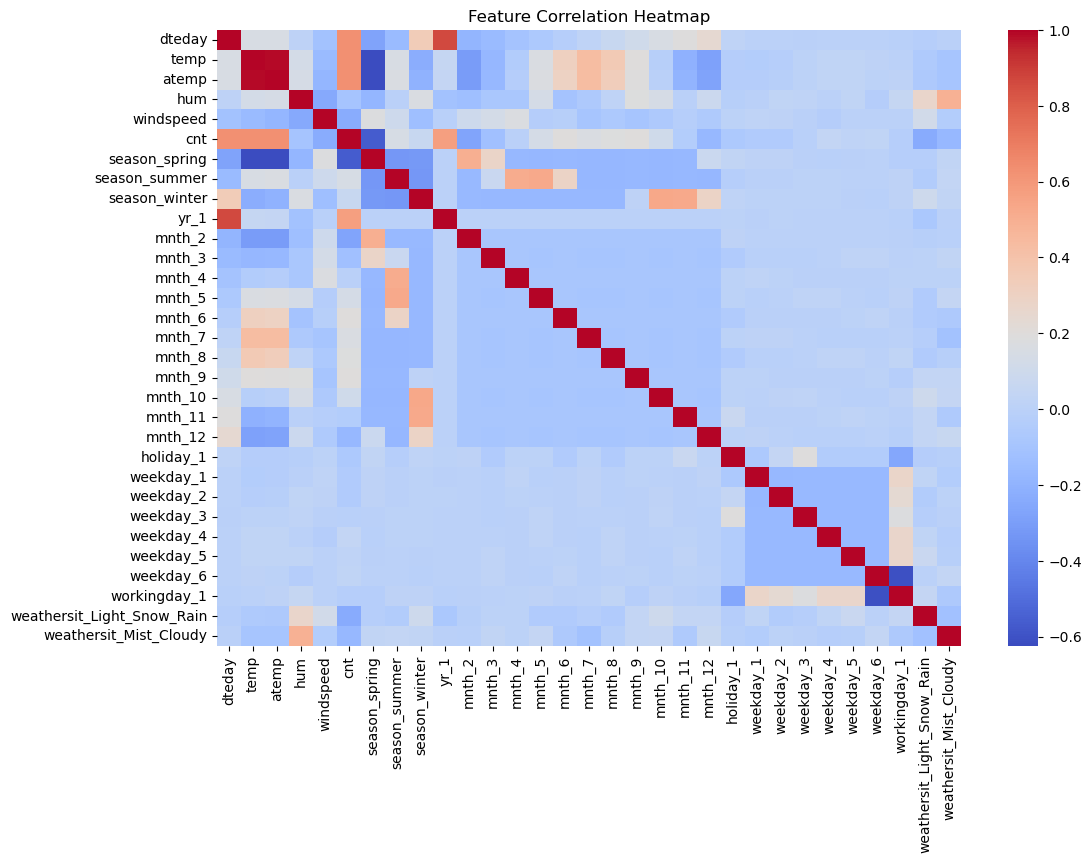

In [33]:
print(df_cleaned.head())
import pandas as pd
import numpy as np

# Ensure df_cleaned exists
if 'df_cleaned' not in locals():
    df_cleaned = df.copy()  # Replace with actual cleaned dataset

# Identify non-numeric columns
non_numeric_cols = df_cleaned.select_dtypes(include=['object', 'category']).columns
print("Non-numeric columns:", non_numeric_cols)

# Convert categorical variables to numeric
df_cleaned = pd.get_dummies(df_cleaned, columns=non_numeric_cols, drop_first=True)

# Compute correlation matrix
correlation_matrix = df_cleaned.corr()

# Plot the heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()


In [45]:
print(df_cleaned.columns)

Index(['dteday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'season_spring',
       'season_summer', 'season_winter', 'yr_1', 'mnth_2', 'mnth_3', 'mnth_4',
       'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11',
       'mnth_12', 'holiday_1', 'weekday_1', 'weekday_2', 'weekday_3',
       'weekday_4', 'weekday_5', 'weekday_6', 'workingday_1',
       'weathersit_Light_Snow_Rain', 'weathersit_Mist_Cloudy'],
      dtype='object')


In [39]:
import os
print(os.listdir())

['Untitled10.ipynb', 'Untitled7.ipynb', '.config', 'Music', '.codegpt', '.condarc', 'Untitled12.ipynb', 'Untitled5.ipynb', 'Untitled1.ipynb', '.DS_Store', '.Untitled1.ipynb.layout', 'untitled1.py', 'get-pip.py', '.CFUserTextEncoding', '.xonshrc', 'Untitled3.ipynb', 'Untitled.ipynb', '.zshrc', 'Untitled4.ipynb', 'Untitled6.ipynb', 'Pictures', 'Untitled11.ipynb', 'churnProject.ipynb', '.zsh_history', 'Untitled2.ipynb', '.ipython', 'Desktop', 'Library', '.matplotlib', '.plcc-helper', 'env', 'housing_updated.csv', 'Public', 'python_coding_practice_i_[exercise]_ag_class.py', '.tcshrc', '.virtual_documents', '.anaconda', 'Credit_EDA_Assignment.ipynb', 'Untitled8.ipynb', 'Movies', 'Applications', '.Trash', '.ipynb_checkpoints', '.zshrc.swp', '.jupyter', 'Documents', '.vscode', '.bash_profile', 'Downloads', '.continuum', 'Untitled9.ipynb', 'untitled.py', '.viminfo', '.zsh_sessions', '.conda', 'Python_Coding_Practice_I_[exercise]_AG_Class.ipynb']


In [49]:
# Convert 'dteday' to datetime format
df['dteday'] = pd.to_datetime(df['dteday'], format="%d-%m-%Y")

# Checking for missing values
missing_values = df.isnull().sum()

# Display summary after conversion
df.info(), missing_values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      730 non-null    datetime64[ns]
 1   season      730 non-null    category      
 2   yr          730 non-null    category      
 3   mnth        730 non-null    category      
 4   holiday     730 non-null    category      
 5   weekday     730 non-null    category      
 6   workingday  730 non-null    category      
 7   weathersit  730 non-null    category      
 8   temp        730 non-null    float64       
 9   atemp       730 non-null    float64       
 10  hum         730 non-null    float64       
 11  windspeed   730 non-null    float64       
 12  casual      730 non-null    int64         
 13  registered  730 non-null    int64         
 14  cnt         730 non-null    int64         
dtypes: category(7), datetime64[ns](1), float64(4), int64(3)
memory usage: 52.2

(None,
 dteday        0
 season        0
 yr            0
 mnth          0
 holiday       0
 weekday       0
 workingday    0
 weathersit    0
 temp          0
 atemp         0
 hum           0
 windspeed     0
 casual        0
 registered    0
 cnt           0
 dtype: int64)

In [55]:
print(df.columns)


Index(['dteday', 'yr', 'holiday', 'workingday', 'temp', 'atemp', 'hum',
       'windspeed', 'casual', 'registered', 'cnt', 'season_spring',
       'season_summer', 'season_winter', 'mnth_2', 'mnth_3', 'mnth_4',
       'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11',
       'mnth_12', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4',
       'weekday_5', 'weekday_6', 'weathersit_Light_Snow_Rain',
       'weathersit_Mist_Cloudy'],
      dtype='object')


In [59]:
X = df.drop(columns=[col for col in ['dteday', 'instant', 'cnt', 'casual', 'registered', 'yr', 'holiday', 'workingday'] if col in df.columns])


In [61]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

# One-hot encode categorical variables
df = pd.get_dummies(df, columns=['season', 'mnth', 'weekday', 'weathersit'], drop_first=True)

# Select features and target variable
X = df.drop(columns=['dteday', 'instant', 'cnt', 'casual', 'registered', 'yr', 'holiday', 'workingday'])
y = df['cnt']

# Standardize numerical columns
scaler = StandardScaler()
X[['temp', 'atemp', 'hum', 'windspeed']] = scaler.fit_transform(X[['temp', 'atemp', 'hum', 'windspeed']])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check shape
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")


KeyError: "None of [Index(['season', 'mnth', 'weekday', 'weathersit'], dtype='object')] are in the [columns]"